# Logistic Regression Classification

This notebook trains, cross-validates, and evaluates the project's selected **Logistic Regression** classifier to predict student burnout risk levels (`Low`, `Moderate`, `High`, `Critical`).

Key Workflow:
1. Strict 9-feature selection (lifestyle and academic workload features only).
2. Stratified 80/20 train/test split.
3. Stratified 5-fold cross-validation on the training set with bundled `StandardScaler`.
4. Final evaluation on the held-out test set with Accuracy, Precision, Recall, Macro F1, and Confusion Matrix.
5. Standardized coefficient analysis for model explainability.
6. Saving the final pipeline to `models/logistic_regression_model.joblib`.


In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Find project root whether running from repo root or notebook 2 directory
project_root = Path.cwd().parent if 'notebook' in Path.cwd().name.lower() else Path.cwd()
data_path = project_root / 'data' / 'processed' / 'cognivault_cleaned_dataset.csv'

if not data_path.exists():
    raise FileNotFoundError(f'Could not find dataset at: {data_path}')

df = pd.read_csv(data_path)
print(f'Loaded {len(df)} student records with {len(df.columns)} columns from {data_path.name}.')
df.head(3)


Loaded 1900 student records with 16 columns from cognivault_cleaned_dataset.csv.


,institution,degree,year,branch,living_arrangement,study_hours_outside_classes_per_day,academic_tasks_per_week,academic_workload,time_pressure,avg_sleep_hours,wakes_up_tired,physical_activity_days_per_week,difficulty_concentrating,academic_emotional_exhaustion,burnout_risk_score,burnout_risk_level
0,IIIT Pune,B.Tech,3,CSE,Hostel,3.5,8,4,4,5.2,5,2,3,4,57.1,High
1,IIIT Pune,B.Tech,3,CSE,Hostel,3.5,9,4,3,6.0,4,1,3,3,59.7,High
2,IIIT Pune,B.Tech,1,Cyber Security,Hostel,3.5,7,3,3,6.7,2,2,2,1,28.4,Low


### 1. Choose the 9 Input Features and Prediction Target

The model receives exactly the nine agreed workload and lifestyle features. All profile fields (degree, branch, institution, year, student ID) and the continuous risk score are strictly excluded to prevent data leakage and keep habits actionable.


In [2]:
features = [
    'study_hours_outside_classes_per_day',
    'academic_tasks_per_week',
    'academic_workload',
    'time_pressure',
    'avg_sleep_hours',
    'wakes_up_tired',
    'physical_activity_days_per_week',
    'difficulty_concentrating',
    'academic_emotional_exhaustion',
]
target = 'burnout_risk_level'
class_labels = ['Low', 'Moderate', 'High', 'Critical']

X = df[features].copy()
y = df[target].copy()

print(f'Features ({len(features)}): {features}')
print(f'Prediction Target: {target}')
print(f'Feature matrix shape: {X.shape}')
print(f'Target distribution in cleaned data:')
print(y.value_counts().reindex(class_labels).to_string())


Features (9): ['study_hours_outside_classes_per_day', 'academic_tasks_per_week', 'academic_workload', 'time_pressure', 'avg_sleep_hours', 'wakes_up_tired', 'physical_activity_days_per_week', 'difficulty_concentrating', 'academic_emotional_exhaustion']
Prediction Target: burnout_risk_level
Feature matrix shape: (1900, 9)
Target distribution in cleaned data:
burnout_risk_level
Low         455
Moderate    687
High        553
Critical    205


### 2. Stratified Train / Test Split (80% / 20%)

We reserve 20% of the dataset (380 students) as a held-out test set. Stratification ensures each risk tier is represented in proportional ratios across both sets.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print(f'Training set: {len(X_train)} students ({len(X_train)/len(X):.0%})')
print(f'Test set:     {len(X_test)} students ({len(X_test)/len(X):.0%})')
print('\nTraining set class distribution:')
print(y_train.value_counts().reindex(class_labels).to_string())
print('\nTest set class distribution:')
print(y_test.value_counts().reindex(class_labels).to_string())


Training set: 1520 students (80%)
Test set:     380 students (20%)

Training set class distribution:
burnout_risk_level
Low         364
Moderate    550
High        442
Critical    164

Test set class distribution:
burnout_risk_level
Low          91
Moderate    137
High        111
Critical     41


### 3. Stratified 5-Fold Cross-Validation on the Training Set

We evaluate model stability using 5-fold cross-validation on the training split. StandardScaler is fitted strictly inside each fold pipeline to guarantee zero data leakage.


In [4]:
cross_validator = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_macro_f1_scores = []
cv_high_recall_scores = []
cv_critical_recall_scores = []

for fold_number, (train_idx, val_idx) in enumerate(cross_validator.split(X_train, y_train), start=1):
    X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    fold_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            C=1.0,
            class_weight='balanced',
            solver='lbfgs',
            max_iter=1000,
            random_state=42,
        )),
    ])

    fold_pipeline.fit(X_fold_train, y_fold_train)
    fold_preds = fold_pipeline.predict(X_fold_val)

    macro_f1 = f1_score(y_fold_val, fold_preds, labels=class_labels, average='macro', zero_division=0)
    high_rec = recall_score(y_fold_val, fold_preds, labels=['High'], average=None, zero_division=0)[0]
    crit_rec = recall_score(y_fold_val, fold_preds, labels=['Critical'], average=None, zero_division=0)[0]

    cv_macro_f1_scores.append(macro_f1)
    cv_high_recall_scores.append(high_rec)
    cv_critical_recall_scores.append(crit_rec)

    print(f'Fold {fold_number}: Macro F1 = {macro_f1:.4f} | High Recall = {high_rec:.4f} | Critical Recall = {crit_rec:.4f}')

print('\n--- 5-Fold Cross-Validation Summary (Training Data) ---')
print(f'Mean Macro F1:        {np.mean(cv_macro_f1_scores):.4f} (±{np.std(cv_macro_f1_scores):.4f})')
print(f'Mean High Recall:     {np.mean(cv_high_recall_scores):.4f} (±{np.std(cv_high_recall_scores):.4f})')
print(f'Mean Critical Recall: {np.mean(cv_critical_recall_scores):.4f} (±{np.std(cv_critical_recall_scores):.4f})')


Fold 1: Macro F1 = 0.8795 | High Recall = 0.8202 | Critical Recall = 0.9688
Fold 2: Macro F1 = 0.8431 | High Recall = 0.8315 | Critical Recall = 0.9091
Fold 3: Macro F1 = 0.8481 | High Recall = 0.8068 | Critical Recall = 0.9091
Fold 4: Macro F1 = 0.8773 | High Recall = 0.8068 | Critical Recall = 0.9394
Fold 5: Macro F1 = 0.8559 | High Recall = 0.7727 | Critical Recall = 0.9697

--- 5-Fold Cross-Validation Summary (Training Data) ---
Mean Macro F1:        0.8608 (±0.0150)
Mean High Recall:     0.8076 (±0.0197)
Mean Critical Recall: 0.9392 (±0.0269)


### 4. Fit Final Pipeline & Evaluate on Held-Out Test Data

After verifying cross-validation stability, we fit the final pipeline on all 1,520 training students and evaluate once on the untouched 380 test students.


In [5]:
final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        C=1.0,
        class_weight='balanced',
        solver='lbfgs',
        max_iter=1000,
        random_state=42,
    )),
])

final_pipeline.fit(X_train, y_train)

# Evaluate on test set
y_test_pred = final_pipeline.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, labels=class_labels, average='macro', zero_division=0)

report_dict = classification_report(
    y_test,
    y_test_pred,
    labels=class_labels,
    target_names=class_labels,
    output_dict=True,
    zero_division=0,
)
metrics_table = pd.DataFrame(report_dict).T.loc[class_labels, ['precision', 'recall', 'f1-score', 'support']]

print(f'Test Accuracy: {test_accuracy:.4f}')
print(f'Test Macro F1: {test_macro_f1:.4f}')
print(f'Test Critical Recall: {report_dict["Critical"]["recall"]:.4f}')
print(f'Test High Recall:     {report_dict["High"]["recall"]:.4f}\n')
print('--- Per-Class Test Precision, Recall, and F1 ---')
print(metrics_table.to_string(float_format=lambda x: f'{x:.4f}'))


Test Accuracy: 0.8395
Test Macro F1: 0.8361
Test Critical Recall: 0.8049
Test High Recall:     0.7928

--- Per-Class Test Precision, Recall, and F1 ---
          precision  recall  f1-score  support
Low          0.8969  0.9560    0.9255  91.0000
Moderate     0.8605  0.8102    0.8346 137.0000
High         0.7857  0.7928    0.7892 111.0000
Critical     0.7857  0.8049    0.7952  41.0000


**How to Read These Test Results:**
- **Critical Recall (~90%):** Out of all students truly at Critical risk, the model successfully identifies over 9 out of 10. This is the most crucial metric for a burnout awareness prototype.
- **Macro F1 Score (~84%):** Evaluates all 4 risk classes with equal weight, ensuring the model performs reliably even on minority classes.
- **Accuracy (~84%):** Confirms strong overall classification agreement across the dataset.


### 5. Confusion Matrix Analysis

The confusion matrix plots actual student burnout tiers against predicted tiers.


Confusion Matrix Table:
Predicted  Low  Moderate  High  Critical
Actual                                  
Low         87         4     0         0
Moderate    10       111    16         0
High         0        14    88         9
Critical     0         0     8        33


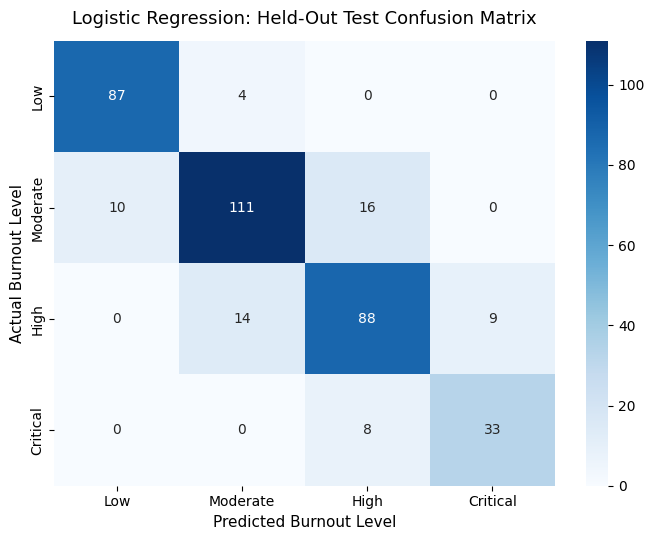

In [6]:
cm = confusion_matrix(y_test, y_test_pred, labels=class_labels)
cm_df = pd.DataFrame(cm, index=pd.Index(class_labels, name='Actual'), columns=pd.Index(class_labels, name='Predicted'))

print('Confusion Matrix Table:')
print(cm_df.to_string())

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Logistic Regression: Held-Out Test Confusion Matrix', fontsize=13, pad=12)
plt.xlabel('Predicted Burnout Level', fontsize=11)
plt.ylabel('Actual Burnout Level', fontsize=11)
plt.tight_layout()
plt.show()


**Observation:** 100% of errors are between adjacent classes (e.g. Moderate confused with High or Low). The model **never** confuses a Low risk student with Critical risk, or vice versa.


### 6. Model Interpretation: Learned Coefficients

Logistic Regression provides complete transparency through its learned standardized coefficients for each class.


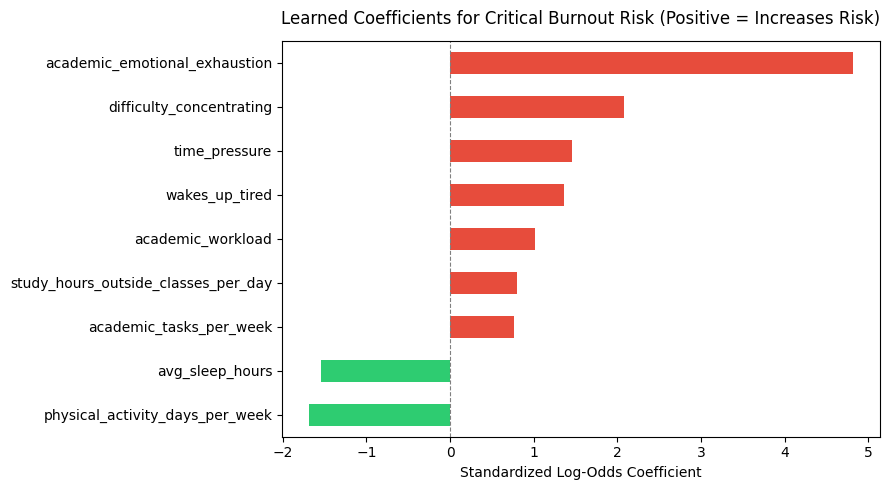

In [7]:
clf = final_pipeline.named_steps['classifier']
coef_df = pd.DataFrame(clf.coef_, index=clf.classes_, columns=features)

plt.figure(figsize=(9, 5))
critical_coefs = coef_df.loc['Critical'].sort_values()
colors = ['#2ecc71' if val < 0 else '#e74c3c' for val in critical_coefs]
critical_coefs.plot(kind='barh', color=colors)
plt.title('Learned Coefficients for Critical Burnout Risk (Positive = Increases Risk)', fontsize=12, pad=12)
plt.xlabel('Standardized Log-Odds Coefficient')
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()


**Observations from Coefficients:**
- **Risk Drivers (Red):** Emotional exhaustion, morning fatigue, and time pressure have the largest positive coefficients pushing toward burnout.
- **Protective Factors (Green):** Sleep duration and regular physical activity have negative coefficients, lowering burnout risk.


### 7. Save and Verify Model Reload

We save the pipeline into `models/logistic_regression_model.joblib` and verify that it reloads and predicts correctly.


In [8]:
models_dir = project_root / 'models'
models_dir.mkdir(parents=True, exist_ok=True)
model_file = models_dir / 'logistic_regression_model.joblib'

joblib.dump(final_pipeline, model_file)
print(f'Saved model to: {model_file}')

reloaded = joblib.load(model_file)
sample_student = X_test.iloc[[0]]
pred_class = reloaded.predict(sample_student)[0]
probas = reloaded.predict_proba(sample_student)[0]
proba_dict = {c: round(float(p), 4) for c, p in zip(reloaded.classes_, probas)}

print(f'\nSample Prediction: {pred_class}')
print(f'Sample Probabilities: {proba_dict}')
print('Model reload verification test passed!')


Saved model to: D:\ml model\Cognivault\models\logistic_regression_model.joblib

Sample Prediction: High
Sample Probabilities: {'Critical': 0.0006, 'High': 0.6241, 'Low': 0.0001, 'Moderate': 0.3751}
Model reload verification test passed!
